# Cadrage du problème de prédiction

Analyse exploratoire simple pour appuyer les choix de cadrage du projet :

1. **Variable cible** : probabilité de victoire de l'équipe locale ;
2. **Unité d'observation** : un match ;
3. **Variables explicatives potentielles** : statistiques d'équipes, de patineurs et de gardiens,
   calculées **avant** le match ;
4. **Saisons à analyser** ;
5. **Stratégie préliminaire de séparation** entraînement / validation / test.

Saison régulière seulement. La saison est notée par son année de début (`2005` = 2005-2006).
Les figures et tableaux sont produits dans les cellules ; avec `SAUVER = True`, les figures sont
aussi enregistrées en PNG (300 dpi) dans `reports/map6009/figures/` et les tableaux en CSV dans
`reports/map6009/tables/` (préfixe `cadrage_`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator, PercentFormatter
from sklearn.metrics import roc_auc_score
from sqlalchemy import text

from nhl_forecast.config import PROJECT_ROOT, get_settings
from nhl_forecast.data.db.mysql import make_engine
from nhl_forecast.data.nhl_collect import stats_table
from nhl_forecast.data.sources.nhl_api import REPORTS
from nhl_forecast.visualization.style import COULEURS, HACHURES, appliquer_style

In [2]:
SAUVER = True  # True : enregistre aussi les figures (PNG) et tableaux (CSV) pour le rapport
FIG_DIR = PROJECT_ROOT / "reports" / "map6009" / "figures"
TAB_DIR = PROJECT_ROOT / "reports" / "map6009" / "tables"

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

GRIS = "#52514e"
appliquer_style()  # couleurs + traits/marqueurs/hachures : lisible en noir et blanc

engine = make_engine()
DB = get_settings().mysql_database
MP_DIR = PROJECT_ROOT / "data" / "raw" / "moneypuck"
FIRST_GAME_ID = 2005_00_0000
SAISON_EN_COURS = 2026  # incomplète : exclue des analyses


def sql(query, **params):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn, params=params)


def saison_de(gid):
    """Saison (année de début) déduite du gameId (ex. 2005020001 -> 2005)."""
    return pd.Series(gid).astype("int64").to_numpy() // 1_000_000


def libelle(s):
    """2005 -> « 2005-06 »."""
    return f"{s}-{(s + 1) % 100:02d}"


def sauver(fig, nom):
    if SAUVER:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{nom}.png", dpi=300, bbox_inches="tight", facecolor="white")


def sauver_tableau(df, nom):
    if SAUVER:
        TAB_DIR.mkdir(parents=True, exist_ok=True)
        df.to_csv(TAB_DIR / f"{nom}.csv", encoding="utf-8")
    return df


def avant_match(df, cle, cols):
    """Moyenne des matchs **précédents** de la même clé (ex. équipe-saison) : information
    connue avant le match. `df` doit être trié chronologiquement ; NaN au premier match."""
    g = df.groupby(cle)
    cumul = g[cols].cumsum() - df[cols].fillna(0)
    n = g.cumcount()
    return cumul.div(n.where(n > 0), axis=0)


def derniers_matchs(df, cle, cols, k=10):
    """Moyenne des `k` matchs précédents (indicateur de forme récente / momentum)."""
    return df.groupby(cle)[cols].transform(lambda s: s.shift().rolling(k, min_periods=3).mean())

## 1. Variable cible et unité d'observation

**Unité d'observation : un match**, vu du côté de l'équipe locale. Chaque match donne une seule
ligne ; les statistiques des deux équipes y sont placées côte à côte (ou sous forme d'écart
local − visiteur).

**Variable cible** : $Y = 1$ si l'équipe locale gagne le match (temps réglementaire, prolongation
ou fusillade), $0$ sinon. Depuis 2005-2006, il n'y a plus de match nul : $Y$ est binaire et le
modèle estime $p = P(Y = 1 \mid \text{information avant le match})$. La probabilité de victoire
du visiteur est $1 - p$.

In [3]:
games = sql(
    """
    SELECT game_id, date, home, away, score_home, score_away, end_game_type
    FROM games
    WHERE league = 'nhl' AND status = 'OFF' AND game_type = 'R'
      AND season_id REGEXP '^[0-9]{8}$' AND season_id >= '20052006'
    """
)
games["gameId"] = games["game_id"].astype("int64")
games["saison"] = saison_de(games["gameId"])
games["date"] = pd.to_datetime(games["date"])
games["home_win"] = (games["score_home"] > games["score_away"]).astype(int)
games["buts"] = games["score_home"] + games["score_away"]
print(
    f"saison en cours ({libelle(SAISON_EN_COURS)}) : "
    f"{(games['saison'] == SAISON_EN_COURS).sum()} matchs, exclus"
)
games = games[games["saison"] < SAISON_EN_COURS].reset_index(drop=True)

print(
    f"{len(games):,} matchs, saisons {libelle(games['saison'].min())} à "
    f"{libelle(games['saison'].max())}"
)
print(
    f"doublons de gameId : {games['gameId'].duplicated().sum()} ; "
    f"scores égaux : {(games['score_home'] == games['score_away']).sum()} ; "
    f"scores manquants : {games[['score_home', 'score_away']].isna().any(axis=1).sum()}"
)

saison en cours (2026-27) : 107 matchs, exclus
25,302 matchs, saisons 2005-06 à 2025-26
doublons de gameId : 0 ; scores égaux : 0 ; scores manquants : 0


### 1.1 Matchs par saison

Le nombre d'équipes passe de 30 à 31 (2017-2018, Vegas) puis 32 (2021-2022, Seattle). Trois
saisons sont écourtées : 2012-2013 (lock-out, 48 matchs par équipe), 2019-2020 (interrompue par
la COVID-19) et 2020-2021 (56 matchs, divisions réalignées, peu ou pas de spectateurs).

In [4]:
equipes = (
    pd.concat(
        [
            games[["saison", "home"]].rename(columns={"home": "e"}),
            games[["saison", "away"]].rename(columns={"away": "e"}),
        ]
    )
    .groupby("saison")["e"]
    .nunique()
)
par_saison = games.groupby("saison").agg(
    matchs=("gameId", "size"),
    victoire_locale=("home_win", "mean"),
    buts_par_match=("buts", "mean"),
    prolongation=("end_game_type", lambda s: (s == "OT").mean()),
    fusillade=("end_game_type", lambda s: (s == "SO").mean()),
)
par_saison.insert(1, "equipes", equipes)
par_saison.insert(2, "matchs_par_equipe", 2 * par_saison["matchs"] / par_saison["equipes"])
par_saison.index = par_saison.index.map(libelle)
sauver_tableau(par_saison, "cadrage_matchs_par_saison")
par_saison.style.format("{:.1%}", subset=["victoire_locale", "prolongation", "fusillade"]).format(
    "{:.2f}", subset=["buts_par_match"]
).format("{:.0f}", subset=["matchs", "equipes", "matchs_par_equipe"])

,matchs,equipes,matchs_par_equipe,victoire_locale,buts_par_match,prolongation,fusillade
saison,,,,,,,
2005-06,1230,30,82,57.4%,6.17,11.1%,11.8%
2006-07,1230,30,82,55.0%,5.89,9.5%,13.3%
2007-08,1230,30,82,53.7%,5.57,9.4%,12.7%
2008-09,1230,30,82,55.9%,5.83,10.0%,12.9%
2009-10,1230,30,82,56.1%,5.68,9.5%,15.0%
2010-11,1230,30,82,51.9%,5.59,12.0%,12.1%
2011-12,1230,30,82,55.9%,5.47,9.7%,14.7%
2012-13,720,30,48,56.8%,5.44,9.0%,13.5%
2013-14,1230,30,82,53.7%,5.49,10.5%,14.5%


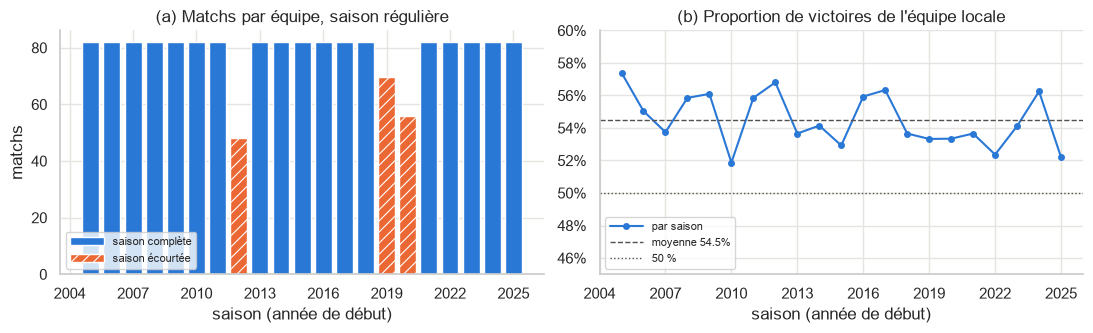

In [5]:
ECOURTEES = {2012: "lock-out", 2019: "COVID-19", 2020: "COVID-19"}
ps = games.groupby("saison").agg(matchs=("gameId", "size"), victoire_locale=("home_win", "mean"))
ps["matchs_par_equipe"] = 2 * ps["matchs"] / equipes

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
for s, v in ps["matchs_par_equipe"].items():
    court = s in ECOURTEES
    ax.bar(
        s,
        v,
        color=COULEURS[1] if court else COULEURS[0],
        hatch="///" if court else "",
        edgecolor="white",
        width=0.8,
    )
ax.legend(
    handles=[
        Patch(facecolor=COULEURS[0], label="saison complète"),
        Patch(facecolor=COULEURS[1], hatch="///", edgecolor="white", label="saison écourtée"),
    ],
    loc="lower left",
    fontsize=8,
)
ax.set(
    title="(a) Matchs par équipe, saison régulière",
    xlabel="saison (année de début)",
    ylabel="matchs",
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

ax = axes[1]
ax.plot(ps.index, ps["victoire_locale"], label="par saison")
moy = games["home_win"].mean()
ax.axhline(moy, color=GRIS, ls="--", lw=1, label=f"moyenne {moy:.1%}")
ax.axhline(0.5, color=GRIS, ls=":", lw=1, label="50 %")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(
    title="(b) Proportion de victoires de l'équipe locale",
    xlabel="saison (année de début)",
    ylim=(0.45, 0.6),
    yticks=np.arange(0.46, 0.61, 0.02),
)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
sauver(fig, "cadrage_matchs_saison")

### 1.2 Issues possibles d'un match

La cible binaire regroupe des victoires de nature différente : une partie des matchs se décide
en prolongation ou en fusillade, où l'issue est proche du hasard. Une variante possible de la
cible (à trois issues : victoire en temps réglementaire, match nul après 60 minutes, défaite) est
gardée en réserve.

In [6]:
issues = pd.crosstab(
    games["home_win"].map({1: "victoire locale", 0: "victoire visiteur"}),
    games["end_game_type"],
    normalize="all",
    margins=True,
    margins_name="total",
)[["REG", "OT", "SO", "total"]].rename(
    columns={"REG": "temps réglementaire", "OT": "prolongation", "SO": "fusillade"}
)
sauver_tableau(issues, "cadrage_issues")
issues.style.format("{:.1%}")

end_game_type,temps réglementaire,prolongation,fusillade,total
home_win,,,,
victoire locale,42.8%,6.6%,5.1%,54.5%
victoire visiteur,34.2%,6.1%,5.2%,45.5%
total,77.0%,12.7%,10.3%,100.0%


In [7]:
# Avantage local selon la façon dont le match s'est terminé
fin = games.groupby("end_game_type")["home_win"].agg(["mean", "size"]).loc[["REG", "OT", "SO"]]
fin.columns = ["victoire_locale", "matchs"]
fin

,victoire_locale,matchs
end_game_type,,
REG,0.555,19478
OT,0.522,3219
SO,0.493,2605


### 1.3 Valeurs de référence pour une probabilité

Avant tout modèle, deux prédictions naïves donnent l'échelle des scores probabilistes
(perte logarithmique et score de Brier, plus bas = meilleur) :

- **pile ou face** : $p = 0{,}5$ pour tous les matchs ;
- **avantage local** : $p$ = proportion de victoires locales observée dans les saisons
  **précédentes** (aucune information sur les équipes).

Un modèle utile devra faire mieux que ces références.

In [8]:
def log_loss(y, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


def brier(y, p):
    return np.mean((p - y) ** 2)


cumul = games.groupby("saison")["home_win"].agg(["sum", "size"]).cumsum().shift()
p_local = (cumul["sum"] / cumul["size"]).rename("p_local")
ref = []
for s, d in games.merge(p_local, left_on="saison", right_index=True).groupby("saison"):
    if np.isnan(d["p_local"].iloc[0]):
        continue
    y = d["home_win"].to_numpy()
    ref.append(
        {
            "saison": libelle(s),
            "p_local": d["p_local"].iloc[0],
            "log_loss_0.5": log_loss(y, 0.5),
            "log_loss_local": log_loss(y, d["p_local"].iloc[0]),
            "brier_0.5": brier(y, 0.5),
            "brier_local": brier(y, d["p_local"].iloc[0]),
        }
    )
ref = pd.DataFrame(ref).set_index("saison")
sauver_tableau(ref, "cadrage_references")
ref.style.format("{:.4f}")

,p_local,log_loss_0.5,log_loss_local,brier_0.5,brier_local
saison,,,,,
2006-07,0.5740,0.6931,0.6892,0.2500,0.2480
2007-08,0.5622,0.6931,0.6916,0.2500,0.2492
2008-09,0.5539,0.6931,0.6863,0.2500,0.2466
2009-10,0.5551,0.6931,0.6858,0.2500,0.2463
2010-11,0.5563,0.6931,0.6953,0.2500,0.2511
2011-12,0.5500,0.6931,0.6864,0.2500,0.2466
2012-13,0.5512,0.6931,0.6844,0.2500,0.2457
2013-14,0.5525,0.6931,0.6910,0.2500,0.2489
2014-15,0.5507,0.6931,0.6899,0.2500,0.2484


## 2. Dimensions des données

Les données brutes ne sont pas à l'échelle du match : il faut les **agréger** pour obtenir une
ligne par match. Une équipe donne 2 lignes par match, un patineur environ 36 (18 par équipe), un
gardien 2 à 4. MoneyPuck ajoute une ligne par **situation de jeu** (`all`, `5on5`, `5on4`,
`4on5`, `other`) ; on compte ici la situation `all`.

In [9]:
# NHL : lignes (saison régulière, saisons terminées) et colonnes de tous les rapports
cols_nhl = sql(
    "SELECT TABLE_NAME AS t, COUNT(*) AS n FROM information_schema.COLUMNS "
    "WHERE TABLE_SCHEMA = :db GROUP BY TABLE_NAME",
    db=DB,
).set_index("t")["n"]
TABLE_PRINCIPALE = {"team": "t_summary", "skater": "summary", "goalie": "g_summary"}
NOMS = {"team": "Équipes", "skater": "Patineurs", "goalie": "Gardiens"}
GRAIN = {"team": "équipe × match", "skater": "patineur × match", "goalie": "gardien × match"}
ID = {"team": "teamId", "skater": "playerId", "goalie": "playerId"}

dims = [
    {
        "source": "NHL",
        "type": "Matchs",
        "granularité": "match",
        "rapports": 1,
        "lignes": len(games),
        "colonnes": cols_nhl["games"],
        "entités": games["home"].nunique(),
        "saisons": f"{libelle(games['saison'].min())} à {libelle(games['saison'].max())}",
    }
]
for entity, table in TABLE_PRINCIPALE.items():
    n = sql(
        f"""SELECT COUNT(*) AS lignes, COUNT(DISTINCT {ID[entity]}) AS entites,
                   MIN(gameId) DIV 1000000 AS s0, MAX(gameId) DIV 1000000 AS s1
            FROM {table} WHERE gameId >= :first AND gameId < :fin
              AND (gameId DIV 10000) % 100 = 2""",
        first=FIRST_GAME_ID,
        fin=SAISON_EN_COURS * 1_000_000,
    ).iloc[0]
    tables = [stats_table(entity, r) for r in REPORTS[entity]]
    dims.append(
        {
            "source": "NHL",
            "type": NOMS[entity],
            "granularité": GRAIN[entity],
            "rapports": len(tables),
            "lignes": n["lignes"],
            "colonnes": int(cols_nhl.reindex(tables).sum()),
            "entités": n["entites"],
            "saisons": f"{libelle(int(n['s0']))} à {libelle(int(n['s1']))}",
        }
    )

In [10]:
# MoneyPuck : saison régulière, situation « all »
mp_t = pd.read_csv(MP_DIR / "teams" / "all_teams.csv", engine="pyarrow")
mp_t = mp_t[(mp_t["playoffGame"] == 0) & (mp_t["season"] < SAISON_EN_COURS)]
mp_g = pd.concat(
    [pd.read_csv(f, engine="pyarrow") for f in sorted((MP_DIR / "goalies").glob("*.csv"))],
    ignore_index=True,
)
mp_g = mp_g[mp_g["season"] < SAISON_EN_COURS]
sk_files = sorted((MP_DIR / "skaters").glob("*.csv"))
n_cols_sk = len(pd.read_csv(sk_files[0], nrows=0).columns)
mp_sk = pd.concat(
    [
        pd.read_csv(f, engine="pyarrow", usecols=["playerId", "gameId", "season", "situation"])
        for f in sk_files
    ],
    ignore_index=True,
)
mp_sk = mp_sk[(mp_sk["situation"] == "all") & (mp_sk["season"] < SAISON_EN_COURS)]

mp_all = mp_t[mp_t["situation"] == "all"]
for typ, df, grain, ncol, ident in [
    (
        "Matchs",
        mp_all[mp_all["home_or_away"] == "HOME"],
        "match (reconstruit)",
        mp_t.shape[1],
        "playerTeam",
    ),
    ("Équipes", mp_all, "équipe × match × situation", mp_t.shape[1], "playerTeam"),
    ("Patineurs", mp_sk, "patineur × match × situation", n_cols_sk, "playerId"),
    (
        "Gardiens",
        mp_g[mp_g["situation"] == "all"],
        "gardien × match × situation",
        mp_g.shape[1],
        "playerId",
    ),
]:
    dims.append(
        {
            "source": "MoneyPuck",
            "type": typ,
            "granularité": grain,
            "rapports": 1,
            "lignes": len(df),
            "colonnes": ncol,
            "entités": df[ident].nunique(),
            "saisons": f"{libelle(df['season'].min())} à {libelle(df['season'].max())}",
        }
    )

dims = pd.DataFrame(dims).set_index(["source", "type"])
dims["lignes_par_match"] = (
    dims["lignes"]
    / dims.loc[(dims.index.get_level_values(1) == "Matchs"), "lignes"]
    .groupby(level=0)
    .first()
    .reindex(dims.index.get_level_values(0))
    .to_numpy()
)
sauver_tableau(dims, "cadrage_dimensions")
dims.style.format(
    {"lignes": "{:,.0f}", "colonnes": "{:,.0f}", "entités": "{:,.0f}", "lignes_par_match": "{:.1f}"}
)

## 3. Variables explicatives potentielles

Toutes les statistiques des sources décrivent ce qui s'est passé **pendant** le match : les
utiliser telles quelles serait une fuite d'information. On les transforme donc en variables
connues **avant** le match :

- **moyenne de la saison à date** (matchs précédents de la même saison) ;
- **forme récente** : moyenne des 10 derniers matchs (indicateur de momentum) ;
- **contexte** : jours de repos depuis le match précédent.

Pour chaque variable, on calcule l'**écart local − visiteur** et son pouvoir discriminant seul
(AUC : 0,5 = aucun signal, 1 = séparation parfaite). C'est un premier tri univarié, pas une
sélection de variables.

### 3.1 Statistiques d'équipes

In [11]:
nhl_t = sql(
    """
    SELECT gameId, teamId, homeRoad, gameDate, goalsFor, goalsAgainst,
           shotsForPerGame AS shotsFor, shotsAgainstPerGame AS shotsAgainst,
           wins, otLosses, powerPlayPct, penaltyKillPct, faceoffWinPct
    FROM t_summary
    WHERE gameId >= :first AND gameId < :fin AND (gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
    fin=SAISON_EN_COURS * 1_000_000,
)
nhl_t["saison"] = saison_de(nhl_t["gameId"])
nhl_t["date"] = pd.to_datetime(nhl_t["gameDate"].str[:10])
nhl_t = nhl_t.sort_values(["date", "gameId"]).reset_index(drop=True)
nhl_t["pts_pct"] = (2 * nhl_t["wins"] + nhl_t["otLosses"]) / 2
nhl_t["diff_buts"] = nhl_t["goalsFor"] - nhl_t["goalsAgainst"]
nhl_t["tirs_pct"] = nhl_t["shotsFor"] / (nhl_t["shotsFor"] + nhl_t["shotsAgainst"])

cle = ["saison", "teamId"]
VAR_NHL = [
    "pts_pct",
    "diff_buts",
    "goalsFor",
    "goalsAgainst",
    "tirs_pct",
    "powerPlayPct",
    "penaltyKillPct",
    "faceoffWinPct",
]
av = avant_match(nhl_t, cle, VAR_NHL).add_suffix("_saison")
av["pts_pct_10"] = derniers_matchs(nhl_t, cle, ["pts_pct"])["pts_pct"]
av["diff_buts_10"] = derniers_matchs(nhl_t, cle, ["diff_buts"])["diff_buts"]
av["repos"] = nhl_t.groupby(cle)["date"].diff().dt.days.clip(upper=5)  # 5 = « 5 jours et + »
av["matchs_joues"] = nhl_t.groupby(cle).cumcount()
eq_nhl = pd.concat([nhl_t[["gameId", "homeRoad"]], av], axis=1)

In [12]:
# MoneyPuck : statistiques avancées (buts attendus xG, tentatives de tir, chances de qualité)
mp = mp_all.copy()
mp["date"] = pd.to_datetime(mp["gameDate"].astype(str), format="%Y%m%d")
mp = mp.sort_values(["date", "gameId"]).reset_index(drop=True)
mp["homeRoad"] = mp["home_or_away"].map({"HOME": "H", "AWAY": "R"})
VAR_MP = [
    "xGoalsPercentage",
    "corsiPercentage",
    "xGoalsFor",
    "xGoalsAgainst",
    "highDangerShotsFor",
    "scoreVenueAdjustedxGoalsFor",
]
av = avant_match(mp, ["season", "playerTeam"], VAR_MP).add_suffix("_saison")
av["xGoalsPercentage_10"] = derniers_matchs(mp, ["season", "playerTeam"], ["xGoalsPercentage"])[
    "xGoalsPercentage"
]
eq_mp = pd.concat([mp[["gameId", "homeRoad"]], av], axis=1)

In [13]:
def ecart_local_visiteur(df, cols):
    """Une ligne par match : écart local − visiteur pour chaque colonne."""
    h = df[df["homeRoad"] == "H"].set_index("gameId")[cols]
    r = df[df["homeRoad"] == "R"].set_index("gameId")[cols]
    return h.sub(r).dropna(how="all")


X = games.set_index("gameId")[["saison", "home_win"]]
for df in (eq_nhl, eq_mp):
    cols = [c for c in df.columns if c not in ("gameId", "homeRoad")]
    X = X.join(ecart_local_visiteur(df, cols))
print(f"{len(X):,} matchs ; variables d'équipe : {X.shape[1] - 2}")
X.describe().T

25,302 matchs ; variables d'équipe : 19


,count,mean,std,min,25%,50%,75%,max
saison,"25,302.000","2,015.103",6.155,"2,005.000","2,010.000","2,015.000","2,021.000","2,025.000"
home_win,"25,302.000",0.545,0.498,0.000,0.000,1.000,1.000,1.000
pts_pct_saison,"24,920.000",-0.002,0.195,-1.000,-0.108,0.000,0.104,1.000
diff_buts_saison,"24,920.000",-0.014,1.063,-14.000,-0.600,0.000,0.578,10.000
goalsFor_saison,"24,920.000",-0.006,0.685,-7.000,-0.380,0.000,0.371,6.000
goalsAgainst_saison,"24,920.000",0.008,0.691,-7.000,-0.389,0.000,0.395,7.000
tirs_pct_saison,"24,920.000",-0.001,0.048,-0.509,-0.030,-0.000,0.028,0.323
powerPlayPct_saison,"24,140.000",-0.001,0.086,-1.000,-0.043,0.000,0.043,1.000
penaltyKillPct_saison,"24,140.000",0.000,0.088,-1.000,-0.045,0.000,0.046,1.000
faceoffWinPct_saison,"24,920.000",-0.000,0.039,-0.278,-0.023,-0.000,0.023,0.261


### 3.2 Statistiques individuelles des patineurs

Une ligne par patineur-match. Pour passer du joueur à l'équipe, une agrégation simple : la somme,
sur les patineurs **alignés** pour le match, de leurs points par match de la saison à date
(l'alignement est connu peu avant le match). D'autres agrégations (pondération par le temps de
glace, meilleurs joueurs, par poste) seront étudiées à l'étape de préparation.

In [14]:
sk = sql(
    """
    SELECT s.gameId, s.playerId, s.teamAbbrev, s.homeRoad, s.positionCode, s.gameDate,
           s.goals, s.points, s.shots, s.plusMinus, t.timeOnIce
    FROM summary s LEFT JOIN timeonice t ON t.gameId = s.gameId AND t.playerId = s.playerId
    WHERE s.gameId >= :first AND s.gameId < :fin AND (s.gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
    fin=SAISON_EN_COURS * 1_000_000,
)
sk["saison"] = saison_de(sk["gameId"])
sk["date"] = pd.to_datetime(sk["gameDate"].str[:10])
sk["timeOnIce"] = sk["timeOnIce"] / 60  # secondes -> minutes
sk["poste"] = np.where(sk["positionCode"] == "D", "Défenseurs", "Attaquants")
sk = sk.sort_values(["date", "gameId"]).reset_index(drop=True)
print(f"{len(sk):,} lignes patineur-match, {sk['playerId'].nunique():,} patineurs")

js = sk.groupby(["saison", "playerId", "poste"]).size().rename("matchs").reset_index()
resume_sk = sk.groupby("poste").agg(
    patineurs=("playerId", "nunique"),
    lignes=("playerId", "size"),
    temps_glace_min=("timeOnIce", "mean"),
    points_par_match=("points", "mean"),
    tirs_par_match=("shots", "mean"),
    matchs_sans_point=("points", lambda s: (s == 0).mean()),
)
resume_sk["matchs_par_joueur_saison_med"] = js.groupby("poste")["matchs"].median()
resume_sk.loc["Tous"] = [
    sk["playerId"].nunique(),
    len(sk),
    sk["timeOnIce"].mean(),
    sk["points"].mean(),
    sk["shots"].mean(),
    (sk["points"] == 0).mean(),
    js["matchs"].median(),
]
sauver_tableau(resume_sk, "cadrage_patineurs_resume")
resume_sk.style.format(
    "{:,.0f}", subset=["patineurs", "lignes", "matchs_par_joueur_saison_med"]
).format("{:.2f}", subset=["temps_glace_min", "points_par_match", "tirs_par_match"]).format(
    "{:.1%}", subset=["matchs_sans_point"]
)

910,628 lignes patineur-match, 3,460 patineurs


,patineurs,lignes,temps_glace_min,points_par_match,tirs_par_match,matchs_sans_point,matchs_par_joueur_saison_med
poste,,,,,,,
Attaquants,"2,290","603,533",14.95,0.49,1.83,63.5%,56
Défenseurs,"1,170","307,095",19.49,0.32,1.37,73.6%,53
Tous,"3,460","910,628",16.48,0.43,1.67,66.9%,55


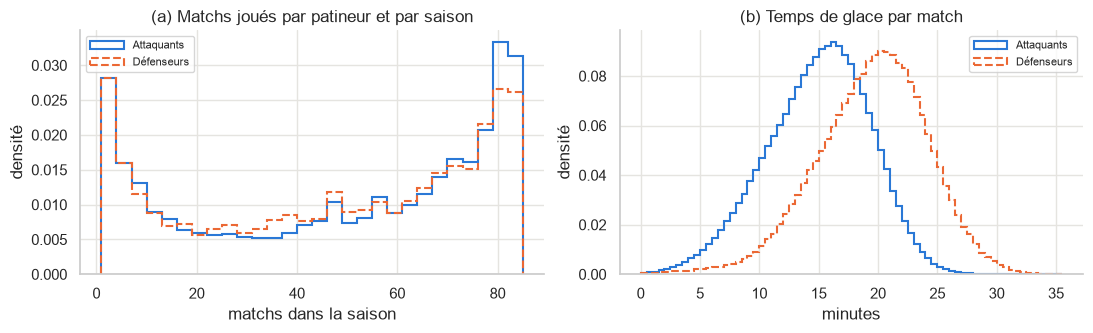

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for k, (poste, d) in enumerate(js.groupby("poste")):
    axes[0].hist(
        d["matchs"],
        bins=np.arange(1, 86, 3),
        density=True,
        histtype="step",
        color=COULEURS[k],
        ls=["-", "--"][k],
        lw=1.5,
        label=poste,
    )
    tg = sk.loc[sk["poste"] == poste, "timeOnIce"].dropna()
    axes[1].hist(
        tg,
        bins=np.arange(0, 36, 0.5),
        density=True,
        histtype="step",
        color=COULEURS[k],
        ls=["-", "--"][k],
        lw=1.5,
        label=poste,
    )
axes[0].set(
    title="(a) Matchs joués par patineur et par saison",
    xlabel="matchs dans la saison",
    ylabel="densité",
)
axes[1].set(title="(b) Temps de glace par match", xlabel="minutes", ylabel="densité")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
sauver(fig, "cadrage_patineurs")

In [16]:
# Points par match de la saison à date (avant le match), puis somme sur les patineurs alignés
sk["pts_pm_avant"] = avant_match(sk, ["saison", "playerId"], ["points"])["points"]
sk["tg_avant"] = avant_match(sk, ["saison", "playerId"], ["timeOnIce"])["timeOnIce"]
agg_sk = (
    sk.groupby(["gameId", "homeRoad"])
    .agg(
        patineurs_pts_saison=("pts_pm_avant", lambda s: s.sum(min_count=10)),
        patineurs_inconnus=("pts_pm_avant", lambda s: s.isna().mean()),
    )
    .reset_index()
)
print(
    "patineurs alignés sans match antérieur dans la saison (médiane par équipe-match) :",
    f"{agg_sk['patineurs_inconnus'].median():.1%}",
)
X = X.join(ecart_local_visiteur(agg_sk, ["patineurs_pts_saison"]))

patineurs alignés sans match antérieur dans la saison (médiane par équipe-match) : 0.0%


### 3.3 Statistiques des gardiens

Le gardien **partant** est l'information clé (connue peu avant le match). Variables : taux
d'arrêts du partant sur la saison à date (NHL) et buts sauvés au-delà des attentes par 60 minutes
(GSAx = xG − buts, MoneyPuck), calculés sur ses matchs précédents.

In [17]:
gk = sql(
    """
    SELECT gameId, playerId, teamAbbrev, homeRoad, gameDate, gamesStarted, timeOnIce,
           shotsAgainst, saves, goalsAgainst
    FROM g_summary
    WHERE gameId >= :first AND gameId < :fin AND (gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
    fin=SAISON_EN_COURS * 1_000_000,
)
gk["saison"] = saison_de(gk["gameId"])
gk["date"] = pd.to_datetime(gk["gameDate"].str[:10])
gk["timeOnIce"] = gk["timeOnIce"] / 60
gk = gk.sort_values(["date", "gameId"]).reset_index(drop=True)
print(f"{len(gk):,} lignes gardien-match, {gk['playerId'].nunique():,} gardiens")

n = gk.groupby(["gameId", "homeRoad"]).agg(
    gardiens=("playerId", "size"), partants=("gamesStarted", "sum")
)
dep = gk[gk["gamesStarted"] == 1]
part_n1 = (
    dep.groupby(["saison", "teamAbbrev", "playerId"])
    .size()
    .groupby(["saison", "teamAbbrev"])
    .agg(lambda s: s.max() / s.sum())
)
resume_gk = pd.Series(
    {
        "gardiens distincts": gk["playerId"].nunique(),
        "lignes gardien-match": len(gk),
        "équipes-matchs avec 1 partant": (n["partants"] == 1).mean(),
        "équipes-matchs avec relève (2 gardiens et +)": (n["gardiens"] > 1).mean(),
        "part des départs du gardien n° 1 (médiane)": part_n1.median(),
        "gardiens partants différents par équipe-saison (médiane)": dep.groupby(
            ["saison", "teamAbbrev"]
        )["playerId"]
        .nunique()
        .median(),
        "taux d'arrêts moyen des partants": dep["saves"].sum() / dep["shotsAgainst"].sum(),
    },
    name="valeur",
).to_frame()
sauver_tableau(resume_gk, "cadrage_gardiens_resume")
resume_gk

54,374 lignes gardien-match, 386 gardiens


,valeur
gardiens distincts,386.000
lignes gardien-match,"54,374.000"
équipes-matchs avec 1 partant,1.000
équipes-matchs avec relève (2 gardiens et +),0.074
part des départs du gardien n° 1 (médiane),0.644
gardiens partants différents par équipe-saison (médiane),3.000
taux d'arrêts moyen des partants,0.909


In [18]:
# Taux d'arrêts du gardien sur la saison à date (tous ses matchs précédents, partant ou relève)
cum = gk.groupby(["saison", "playerId"])[["saves", "shotsAgainst"]].cumsum()
cum = cum - gk[["saves", "shotsAgainst"]]
gk["sv_avant"] = (cum["saves"] / cum["shotsAgainst"]).where(cum["shotsAgainst"] >= 50)
partant = gk[gk["gamesStarted"] == 1].rename(columns={"sv_avant": "partant_sv_saison"})
X = X.join(ecart_local_visiteur(partant, ["partant_sv_saison"]))

# MoneyPuck : GSAx par 60 min du partant (gardien ayant le plus joué pour l'équipe dans le match)
g = mp_g[mp_g["situation"] == "all"].copy()
g["date"] = pd.to_datetime(g["gameDate"].astype(str), format="%Y%m%d")
g = g.sort_values(["date", "gameId"]).reset_index(drop=True)
g["GSAx"] = g["xGoals"] - g["goals"]
cum = g.groupby(["season", "playerId"])[["GSAx", "icetime"]].cumsum() - g[["GSAx", "icetime"]]
g["partant_gsax60_saison"] = (3600 * cum["GSAx"] / cum["icetime"]).where(cum["icetime"] >= 3 * 3600)
g["homeRoad"] = g["home_or_away"].map({"HOME": "H", "AWAY": "R"})
rang = g.groupby(["gameId", "playerTeam"])["icetime"].rank(ascending=False, method="first")
X = X.join(ecart_local_visiteur(g[rang == 1], ["partant_gsax60_saison"]))

### 3.4 Synthèse des variables candidates

AUC de l'écart local − visiteur, seul, pour prédire la victoire locale. Une AUC inférieure à
0,5 signifie que la relation est inversée (ex. buts accordés : plus c'est haut, moins on gagne) ;
on affiche $\max(\text{AUC}, 1 - \text{AUC})$ avec le sens de la relation. La couverture est la
proportion des matchs pour lesquels la variable est disponible (NaN en début de saison, et
MoneyPuck seulement depuis 2008-2009).

In [19]:
DESCRIPTION = {
    "pts_pct_saison": ("Équipe (NHL)", "% des points obtenus, saison à date"),
    "diff_buts_saison": ("Équipe (NHL)", "différentiel de buts par match"),
    "goalsFor_saison": ("Équipe (NHL)", "buts marqués par match"),
    "goalsAgainst_saison": ("Équipe (NHL)", "buts accordés par match"),
    "tirs_pct_saison": ("Équipe (NHL)", "part des tirs au but"),
    "powerPlayPct_saison": ("Équipe (NHL)", "efficacité en avantage numérique"),
    "penaltyKillPct_saison": ("Équipe (NHL)", "efficacité en désavantage numérique"),
    "faceoffWinPct_saison": ("Équipe (NHL)", "% des mises en jeu gagnées"),
    "pts_pct_10": ("Équipe (NHL)", "% des points, 10 derniers matchs (momentum)"),
    "diff_buts_10": ("Équipe (NHL)", "différentiel de buts, 10 derniers matchs (momentum)"),
    "repos": ("Équipe (NHL)", "jours de repos (contexte)"),
    "matchs_joues": ("Équipe (NHL)", "matchs déjà joués dans la saison (contexte)"),
    "xGoalsPercentage_saison": ("Équipe (MoneyPuck)", "part des buts attendus (xG%)"),
    "corsiPercentage_saison": ("Équipe (MoneyPuck)", "part des tentatives de tir (Corsi%)"),
    "xGoalsFor_saison": ("Équipe (MoneyPuck)", "buts attendus pour par match"),
    "xGoalsAgainst_saison": ("Équipe (MoneyPuck)", "buts attendus contre par match"),
    "highDangerShotsFor_saison": ("Équipe (MoneyPuck)", "tirs de grande qualité par match"),
    "scoreVenueAdjustedxGoalsFor_saison": ("Équipe (MoneyPuck)", "xG pour ajustés (score, lieu)"),
    "xGoalsPercentage_10": ("Équipe (MoneyPuck)", "xG%, 10 derniers matchs (momentum)"),
    "patineurs_pts_saison": ("Patineurs (NHL)", "somme des points/match des patineurs alignés"),
    "partant_sv_saison": ("Gardiens (NHL)", "taux d'arrêts du partant, saison à date"),
    "partant_gsax60_saison": ("Gardiens (MoneyPuck)", "GSAx/60 du partant, saison à date"),
}

lignes = []
for v, (groupe, desc) in DESCRIPTION.items():
    m = X[v].notna()
    auc = roc_auc_score(X.loc[m, "home_win"], X.loc[m, v])
    lignes.append(
        {
            "variable": v,
            "groupe": groupe,
            "description": desc,
            "AUC": max(auc, 1 - auc),
            "sens": "+" if auc >= 0.5 else "−",
            "couverture": m.mean(),
        }
    )
variables = pd.DataFrame(lignes).set_index("variable").sort_values("AUC", ascending=False)
sauver_tableau(variables, "cadrage_variables")
variables.style.format({"AUC": "{:.3f}", "couverture": "{:.1%}"})

,groupe,description,AUC,sens,couverture
variable,,,,,
xGoalsPercentage_saison,Équipe (MoneyPuck),part des buts attendus (xG%),0.590,+,83.7%
corsiPercentage_saison,Équipe (MoneyPuck),part des tentatives de tir (Corsi%),0.586,+,83.7%
diff_buts_saison,Équipe (NHL),différentiel de buts par match,0.582,+,98.5%
tirs_pct_saison,Équipe (NHL),part des tirs au but,0.582,+,98.5%
xGoalsPercentage_10,Équipe (MoneyPuck),"xG%, 10 derniers matchs (momentum)",0.579,+,81.3%
pts_pct_saison,Équipe (NHL),"% des points obtenus, saison à date",0.577,+,98.5%
scoreVenueAdjustedxGoalsFor_saison,Équipe (MoneyPuck),"xG pour ajustés (score, lieu)",0.574,+,83.7%
patineurs_pts_saison,Patineurs (NHL),somme des points/match des patineurs alignés,0.574,+,98.5%
xGoalsFor_saison,Équipe (MoneyPuck),buts attendus pour par match,0.572,+,83.7%


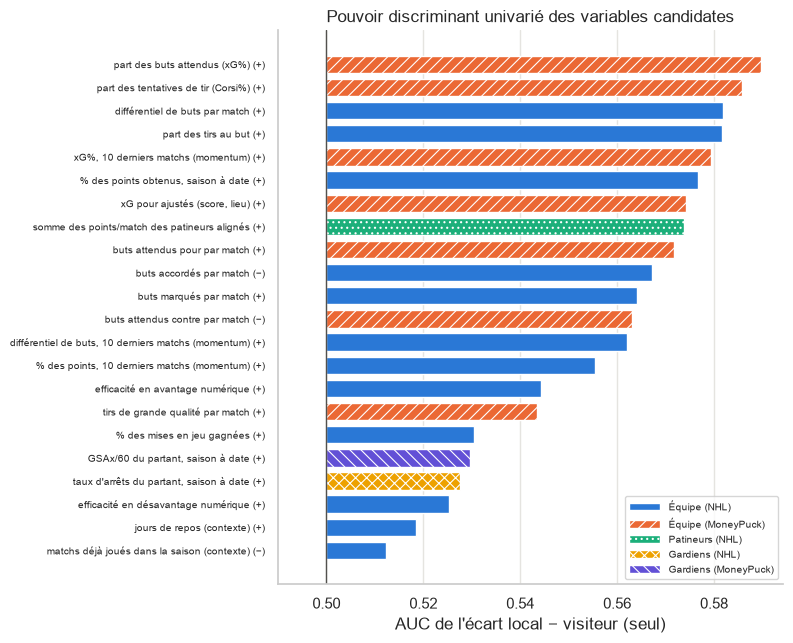

In [20]:
GROUPES = list(dict.fromkeys(g for g, _ in DESCRIPTION.values()))
style_g = {g: (COULEURS[k], HACHURES[k]) for k, g in enumerate(GROUPES)}
v = variables.sort_values("AUC")

fig, ax = plt.subplots(figsize=(8, 6.5))
for i, (_, r) in enumerate(v.iterrows()):
    c, h = style_g[r["groupe"]]
    ax.barh(i, r["AUC"] - 0.5, left=0.5, color=c, hatch=h, edgecolor="white", height=0.75)
ax.set_yticks(
    range(len(v)), [f"{r['description']} ({r['sens']})" for _, r in v.iterrows()], fontsize=7.5
)
ax.axvline(0.5, color=GRIS, lw=1)
ax.set(
    xlim=(0.49, None),
    xlabel="AUC de l'écart local − visiteur (seul)",
    title="Pouvoir discriminant univarié des variables candidates",
)
ax.legend(
    handles=[
        Patch(facecolor=c, hatch=h, edgecolor="white", label=g) for g, (c, h) in style_g.items()
    ],
    fontsize=7.5,
    loc="lower right",
)
ax.grid(axis="y", visible=False)
fig.tight_layout()
sauver(fig, "cadrage_auc_variables")

Relation entre l'écart avant-match et la proportion de victoires locales, par décile de l'écart.
Une relation proche d'une droite favorise un modèle simple (régression logistique) ; une
courbure ou un plateau suggère des effets non linéaires.

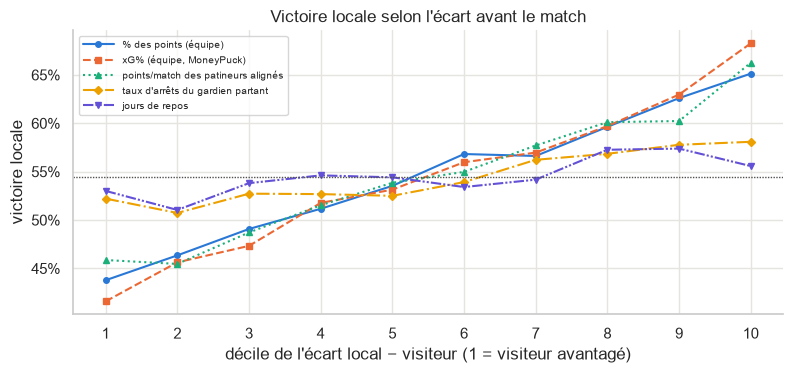

In [21]:
SERIES = {
    "pts_pct_saison": "% des points (équipe)",
    "xGoalsPercentage_saison": "xG% (équipe, MoneyPuck)",
    "patineurs_pts_saison": "points/match des patineurs alignés",
    "partant_sv_saison": "taux d'arrêts du gardien partant",
    "repos": "jours de repos",
}
fig, ax = plt.subplots(figsize=(8, 3.8))
for nom, lab in SERIES.items():
    d = X[[nom, "home_win"]].dropna()
    q = pd.qcut(d[nom].rank(method="first"), 10, labels=range(1, 11))
    ax.plot(d.groupby(q, observed=True)["home_win"].mean(), label=lab)
ax.axhline(games["home_win"].mean(), color=GRIS, lw=1, ls=(0, (1, 1)), marker="")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set(
    xticks=range(1, 11),
    xlabel="décile de l'écart local − visiteur (1 = visiteur avantagé)",
    ylabel="victoire locale",
    title="Victoire locale selon l'écart avant le match",
)
ax.legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
sauver(fig, "cadrage_deciles_variables")

Même pour les meilleures variables, l'AUC reste modeste (autour de 0,6) : une grande part du
résultat d'un match de hockey est aléatoire. Cela justifie l'accent sur la **calibration** des
probabilités plutôt que sur la seule exactitude.

Les variables précoces sont aussi plus bruitées : le pouvoir discriminant dépend du nombre de
matchs déjà joués dans la saison (démarrage à froid).

In [22]:
n_local = eq_nhl[eq_nhl["homeRoad"] == "H"].set_index("gameId")["matchs_joues"]
X["tranche"] = pd.cut(
    n_local.reindex(X.index),
    [-1, 9, 19, 39, 59, 100],
    labels=["1-10", "11-20", "21-40", "41-60", "61+"],
)
froid = X.groupby("tranche", observed=True).apply(
    lambda d: pd.Series(
        {
            "matchs": len(d),
            **{
                lab: roc_auc_score(d.loc[d[v].notna(), "home_win"], d.loc[d[v].notna(), v])
                for v, lab in [
                    ("pts_pct_saison", "AUC % des points"),
                    ("xGoalsPercentage_saison", "AUC xG%"),
                ]
            },
        }
    ),
    include_groups=False,
)
froid.index.name = "nième match de l'équipe locale"
froid.style.format("{:.3f}").format("{:,.0f}", subset=["matchs"])

,matchs,AUC % des points,AUC xG%
nième match de l'équipe locale,,,
1-10,"3,231",0.531,0.554
11-20,"3,206",0.533,0.565
21-40,"6,440",0.590,0.604
41-60,"6,196",0.586,0.596
61+,"6,229",0.617,0.607


## 4. Saisons à analyser et séparation des données

**Saisons** : de 2005-2006 (début des fusillades, fin des matchs nuls, données NHL disponibles) à
2025-2026 (dernière saison terminée). MoneyPuck commence en 2008-2009 : les saisons 2005 à 2007
servent surtout d'**historique d'amorçage** (cotes Elo, statistiques de carrière). La saison
2026-2027, en cours, est exclue.

**Séparation chronologique** (jamais aléatoire : un match du passé ne doit pas être prédit avec
de l'information du futur) :

| Ensemble | Saisons | Rôle |
|---|---|---|
| Amorçage | 2005-06 à 2007-08 | historique seulement (Elo, carrière) |
| Développement | 2008-09 à 2023-24 | entraînement et validation par plis *walk-forward* |
| Test | 2024-25 à 2025-26 | évaluation finale, utilisé une seule fois |

**Validation croisée temporelle (*walk-forward*, fenêtre croissante).** Le développement est
découpé en $k = 8$ plis. Pour le pli $k$, le modèle est entraîné sur toutes les saisons de
2008-2009 jusqu'à la saison $t_k - 1$, puis validé sur la saison $t_k$
($t_k$ = 2016-2017, …, 2023-2024). Le score de validation d'un modèle (perte logarithmique,
Brier, calibration) est la moyenne sur les plis, pondérée par le nombre de matchs, avec sa
dispersion d'un pli à l'autre. Il sert à choisir les hyperparamètres et à comparer les familles
de modèles.

Règles pour éviter les fuites d'information :

- tout ce qui est **appris** des données (normalisation, ACP, imputation, recalibration
  Platt/isotonique) est ajusté sur la partie entraînement de chaque pli seulement ;
- les variables « saison à date » et « 10 derniers matchs » n'utilisent que les matchs
  précédents : elles peuvent être calculées une seule fois pour tous les plis.

**Test.** Même logique, appliquée une seule fois à la fin : modèle final entraîné sur
2008-2009 à 2023-2024 et évalué sur 2024-2025, puis réentraîné en ajoutant 2024-2025 et évalué
sur 2025-2026.

Les saisons écourtées (2012, 2019, 2020) restent dans l'entraînement mais seront signalées
(variable indicatrice ou analyse de sensibilité) ; les plis validés sur 2019 et 2020 ont moins de
matchs, d'où la moyenne pondérée.

In [23]:
ENSEMBLES = {
    "Amorçage": range(2005, 2008),
    "Développement": range(2008, 2024),
    "Test": range(2024, 2026),
}
DEBUT_ENTRAINEMENT = 2008
PLIS_VALIDATION = range(2016, 2024)  # saison de validation t_k de chaque pli
PLIS_TEST = range(2024, 2026)
ens_de = {s: e for e, ss in ENSEMBLES.items() for s in ss}
games["ensemble"] = games["saison"].map(ens_de)

sep = (
    games.groupby("ensemble", sort=False)
    .agg(
        saisons=("saison", lambda s: f"{libelle(s.min())} à {libelle(s.max())}"),
        n_saisons=("saison", "nunique"),
        matchs=("gameId", "size"),
        victoire_locale=("home_win", "mean"),
        buts_par_match=("buts", "mean"),
        fusillade=("end_game_type", lambda s: (s == "SO").mean()),
    )
    .reindex(ENSEMBLES)
)
sep["part_des_matchs"] = sep["matchs"] / sep["matchs"].sum()
sep["matchs_avec_moneypuck"] = games.groupby("ensemble")["gameId"].apply(
    lambda g: g.isin(mp_all["gameId"]).mean()
)
sauver_tableau(sep, "cadrage_separation")
sep.style.format(
    {
        "matchs": "{:,.0f}",
        "victoire_locale": "{:.1%}",
        "buts_par_match": "{:.2f}",
        "fusillade": "{:.1%}",
        "part_des_matchs": "{:.1%}",
        "matchs_avec_moneypuck": "{:.1%}",
    }
)

,saisons,n_saisons,matchs,victoire_locale,buts_par_match,fusillade,part_des_matchs,matchs_avec_moneypuck
ensemble,,,,,,,,
Amorçage,2005-06 à 2007-08,3,"3,690",55.4%,5.88,12.6%,14.6%,0.0%
Développement,2008-09 à 2023-24,16,"18,988",54.3%,5.80,10.2%,75.0%,100.0%
Test,2024-25 à 2025-26,2,"2,624",54.2%,6.17,7.5%,10.4%,100.0%


In [24]:
# Plis walk-forward : entraînement = saisons [2008, t), évaluation = saison t
n_s = games.groupby("saison").size()
p_s = games.groupby("saison")["home_win"].mean()
plis = []
for role, saisons in [("validation", PLIS_VALIDATION), ("test", PLIS_TEST)]:
    for k, t in enumerate(saisons, start=1):
        plis.append(
            {
                "pli": f"{'V' if role == 'validation' else 'T'}{k}",
                "rôle": role,
                "entraînement": f"{libelle(DEBUT_ENTRAINEMENT)} à {libelle(t - 1)}",
                "saisons_entraînement": t - DEBUT_ENTRAINEMENT,
                "matchs_entraînement": n_s.loc[DEBUT_ENTRAINEMENT : t - 1].sum(),
                "évaluation": libelle(t),
                "matchs_évaluation": n_s[t],
                "victoire_locale_évaluation": p_s[t],
                "remarque": f"saison écourtée ({ECOURTEES[t]})" if t in ECOURTEES else "",
            }
        )
plis = pd.DataFrame(plis).set_index("pli")
sauver_tableau(plis, "cadrage_plis_walk_forward")
plis.style.format(
    {
        "matchs_entraînement": "{:,.0f}",
        "matchs_évaluation": "{:,.0f}",
        "victoire_locale_évaluation": "{:.1%}",
    }
)

,rôle,entraînement,saisons_entraînement,matchs_entraînement,évaluation,matchs_évaluation,victoire_locale_évaluation,remarque
pli,,,,,,,,
V1,validation,2008-09 à 2015-16,8,"9,330",2016-17,"1,230",55.9%,
V2,validation,2008-09 à 2016-17,9,"10,560",2017-18,"1,271",56.3%,
V3,validation,2008-09 à 2017-18,10,"11,831",2018-19,"1,271",53.7%,
V4,validation,2008-09 à 2018-19,11,"13,102",2019-20,"1,082",53.3%,saison écourtée (COVID-19)
V5,validation,2008-09 à 2019-20,12,"14,184",2020-21,868,53.3%,saison écourtée (COVID-19)
V6,validation,2008-09 à 2020-21,13,"15,052",2021-22,"1,312",53.7%,
V7,validation,2008-09 à 2021-22,14,"16,364",2022-23,"1,312",52.4%,
V8,validation,2008-09 à 2022-23,15,"17,676",2023-24,"1,312",54.1%,
T1,test,2008-09 à 2023-24,16,"18,988",2024-25,"1,312",56.2%,


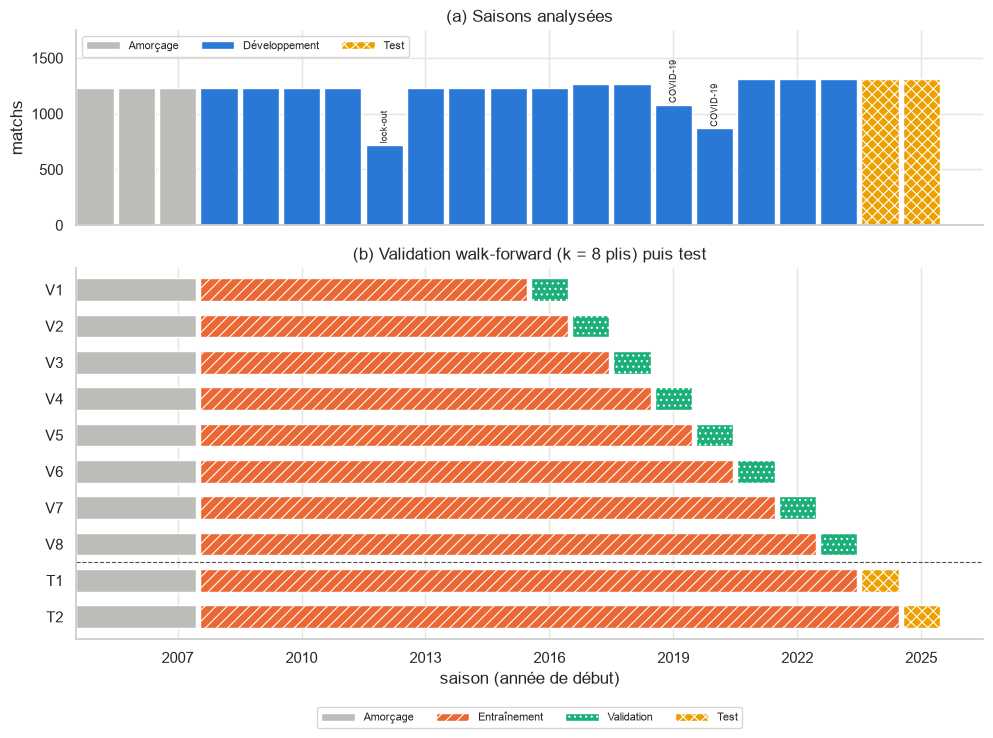

In [25]:
STYLE_E = {
    "Amorçage": ("#bdbcb8", ""),  # gris clair, uni : historique seulement
    "Développement": (COULEURS[0], ""),
    "Entraînement": (COULEURS[1], "///"),
    "Validation": (COULEURS[2], "..."),
    "Test": (COULEURS[3], "xxx"),
}


def legende(ax, noms, **kw):
    ax.legend(
        handles=[
            Patch(facecolor=STYLE_E[e][0], hatch=STYLE_E[e][1], edgecolor="white", label=e)
            for e in noms
        ],
        fontsize=8,
        **kw,
    )


def bloc(ax, y, debut, fin, style):
    """Segment horizontal couvrant les saisons debut à fin (incluses)."""
    c, h = STYLE_E[style]
    ax.barh(
        y, fin - debut + 0.9, left=debut - 0.45, height=0.62, color=c, hatch=h, edgecolor="white"
    )


fig, axes = plt.subplots(2, 1, figsize=(10, 7.4), height_ratios=[1, 1.9], sharex=True)
ax = axes[0]
for s, n in n_s.items():
    c, h = STYLE_E[ens_de[s]]
    ax.bar(s, n, color=c, hatch=h, edgecolor="white", width=0.9)
    if s in ECOURTEES:
        ax.text(s, n + 15, ECOURTEES[s], ha="center", va="bottom", fontsize=6.5, rotation=90)
ax.set(ylabel="matchs", title="(a) Saisons analysées", ylim=(0, 1750))
legende(ax, ENSEMBLES, ncol=3, loc="upper left")

ax = axes[1]
lignes = [(t, "Validation") for t in PLIS_VALIDATION] + [(t, "Test") for t in PLIS_TEST]
for i, (t, role) in enumerate(lignes):
    y = len(lignes) - i
    bloc(ax, y, 2005, DEBUT_ENTRAINEMENT - 1, "Amorçage")
    bloc(ax, y, DEBUT_ENTRAINEMENT, t - 1, "Entraînement")
    bloc(ax, y, t, t, role)
ax.axhline(len(PLIS_TEST) + 0.5, color=GRIS, lw=0.8, ls="--", marker="")
ax.set_yticks(range(len(lignes), 0, -1), plis.index)
ax.set(
    title=f"(b) Validation walk-forward (k = {len(PLIS_VALIDATION)} plis) puis test",
    xlabel="saison (année de début)",
    ylim=(0.4, len(lignes) + 0.6),
)
legende(
    ax,
    ["Amorçage", "Entraînement", "Validation", "Test"],
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
sauver(fig, "cadrage_separation")

Stabilité de la cible entre les ensembles : la proportion de victoires locales et le nombre de
buts par match varient peu, mais la proportion de fusillades a baissé (prolongation à 3 contre 3
depuis 2015-2016). Les plis walk-forward mesurent justement si un modèle entraîné sur les saisons
passées reste calibré sur la saison suivante, et si sa performance est stable d'une saison à
l'autre.